# Geometrical model with Julia

This notebook execute some Julia scripts. At first, these scripts were written in Python, but it was slow. I rewrote them in Julia in an attempt to accelerate the generation of ellipsoids. Below you can find a tool to :
1. Generate a benchmark population to use FAMILY.
2. Generate the correspondig .fits

In [3]:
include("EllipsoidFragmentation.jl")
include("ProjectionMapper.jl")
include("SimulationIO.jl")

import .EllipsoidFragmentation
import .ProjectionMapper
import .SimulationIO

import Plots
import DataFrames
import Statistics

In [4]:
import Plots

function show_sample(child, plots)
    pxy, pxz, pyz = plots
    P = EllipsoidFragmentation.sample_points_child(child; sampling=1000)
    X = P[1, :]
    Y = P[2, :]
    Z = P[3, :]

    Plots.scatter!(pxy, X, Y)
    Plots.scatter!(pxz, X, Z)
    Plots.scatter!(pyz, Y, Z)
end

function plot_projections(projections, childs; npoints::Int=200, equal_aspect::Bool=true, sampling::Bool=false, merging::Bool=true)
    function ellipse_points(xc, yc, a, b, θ; n=npoints)
        t = range(0, 2π; length=n)
        ct, st = cos(θ), sin(θ)
        x = xc .+ a .* cos.(t) .* ct .- b .* sin.(t) .* st
        y = yc .+ a .* cos.(t) .* st .+ b .* sin.(t) .* ct
        return x, y
    end

    pxy = Plots.plot(title="XY", xlabel="x", ylabel="y", legend=false)
    pxz = Plots.plot(title="XZ", xlabel="x", ylabel="z", legend=false)
    pyz = Plots.plot(title="YZ", xlabel="y", ylabel="z", legend=false)

    for (axis, p) in ((:xy, pxy), (:xz, pxz), (:yz, pyz))
        if merging
            levels = sort(unique(e.level for e in projections[axis]))
            for level in levels
                ellipses = filter(e -> e.level == level, projections[axis])
                polygons = ProjectionMapper.merge_overlap(ellipses)
            
                for polygon in polygons
                    x, y = ProjectionMapper.polygon_xy(polygon)
                    Plots.plot!(p, x, y)
                end
            end
        else
            for ellipse in projections[axis]
                x, y = ellipse_points(ellipse.xo, ellipse.yo, ellipse.a, ellipse.b, ellipse.angle)
                Plots.plot!(p, x, y)
            end
        end

        if equal_aspect
            Plots.plot!(p, aspect_ratio=:equal)
        end
    end

    if sampling
        for child in childs
            show_sample(child, [pxy, pxz, pyz])
        end
    end

    return Plots.plot(pxy, pxz, pyz; layout=(1, 3), size=(1200, 400))
end

plot_projections (generic function with 1 method)

In [5]:
# Load config
config = SimulationIO.load_config("config.toml")

# Create a population
parents = SimulationIO.create_initial_parents(config; seed=42)
gen = SimulationIO.create_generator(config, parents)

# Fragment them
ellipsoids = EllipsoidFragmentation.build_population!(gen; verbose=true)

println("Nombre total d'ellipsoïdes: ", length(ellipsoids))

Building level 1 with 25 parents...


Progress: 100%|█████████████████████████████████████████| Time: 0:00:02


  Created 30 children
Building level 2 with 30 parents...


Progress: 100%|█████████████████████████████████████████| Time: 0:00:02


  Created 39 children
Building level 3 with 39 parents...


...

  Created 52 children


Progress:  21%|█████████                                |  ETA: 0:00:07

Building level 4 with 52 parents...


Progress: 100%|█████████████████████████████████████████| Time: 0:00:06


  Created 64 children
Nombre total d'ellipsoïdes: 210


# Visualise the projections

Projecting ellipsoids... 100%|██████████████████████████| Time: 0:00:00


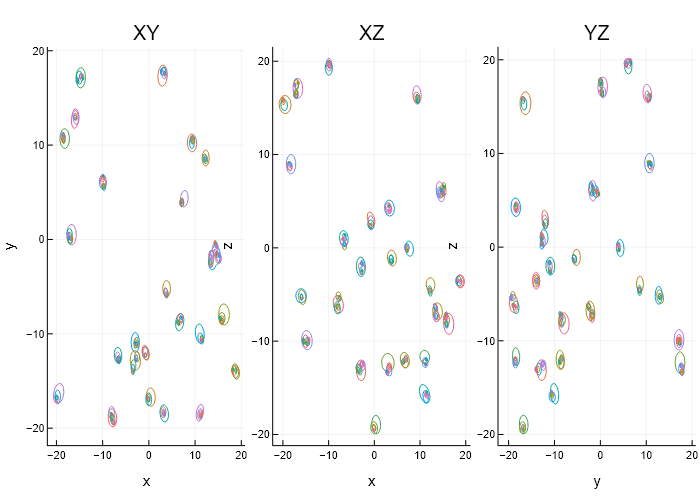

In [6]:
projector = ProjectionMapper.Projector(ellipsoids)
projections = ProjectionMapper.project_population(projector)

fig = plot_projections(projections, ellipsoids, merging=true)
Plots.display(fig)  

# Synthetic column density map

In [7]:
function make_linear_grid(xmin, xmax, ymin, ymax, Nx, Ny)
    xs = range(xmin, xmax, length=Nx)
    ys = range(ymin, ymax, length=Ny)

    delta_x = Nx > 1 ? (xmax - xmin) / (Nx - 1) : 1.0
    delta_y = Ny > 1 ? (ymax - ymin) / (Ny - 1) : 1.0

    offset_x = xmin   # centre du pixel i=1
    offset_y = ymin   # centre du pixel j=1

    return xs, ys, delta_x, delta_y, offset_x, offset_y
end

function bounding_box_from_ellipses(proj; nsig=4.0)
    isempty(proj) && throw(ArgumentError("The ellipse collection is empty."))

    xmin, xmax = Inf, -Inf
    ymin, ymax = Inf, -Inf

    for e in proj
        c, s = cos(e.angle), sin(e.angle)

        hx = nsig * sqrt((e.a * c)^2 + (e.b * s)^2)
        hy = nsig * sqrt((e.a * s)^2 + (e.b * c)^2)

        xmin = min(xmin, e.xo - hx)
        xmax = max(xmax, e.xo + hx)
        ymin = min(ymin, e.yo - hy)
        ymax = max(ymax, e.yo + hy)
    end

    return xmin, xmax, ymin, ymax
end

function add_ellipse_gaussian!(
    M, xs, ys, e::ProjectionMapper.Ellipse;
    A=10.0,
)
    Ny, Nx = size(M)

    @assert length(xs) == Nx
    @assert length(ys) == Ny
    @assert e.a > 0 && e.b > 0

    c = cos(e.angle)
    s = sin(e.angle)

    for j in 1:Ny
        for i in 1:Nx
            dx = xs[i] - e.xo
            dy = ys[j] - e.yo

            xr =  c * dx + s * dy
            yr = -s * dx + c * dy

            M[j, i] += A * exp(
                -0.5 * ((xr / e.a)^2 + (yr / e.b)^2)
            )
        end
    end

    return M
end

xmin, xmax, ymin, ymax = bounding_box_from_ellipses(projections[:xy], nsig=4.0)

Nx = 256
Ny = 256

xs, ys, delta_x, delta_y, offset_x, offset_y = make_linear_grid(xmin, xmax, ymin, ymax, Nx, Ny)

CRPIX1 = 1.0
CRPIX2 = 1.0
CRVAL1 = offset_x
CRVAL2 = offset_y
CDELT1 = delta_x
CDELT2 = delta_y

M = zeros(Float64, Ny, Nx)

for e in projections[:xy]
    add_ellipse_gaussian!(M, xs, ys, e; A=10.0)
end

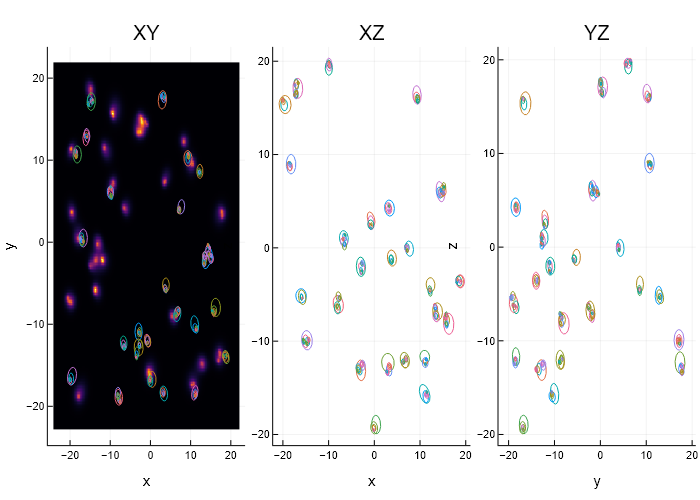

In [8]:
fig = plot_projections(projections, ellipsoids)
Plots.heatmap!(fig, xs, ys, M; z_order=:back, aspect_ratio=:equal)

Plots.display(fig) 


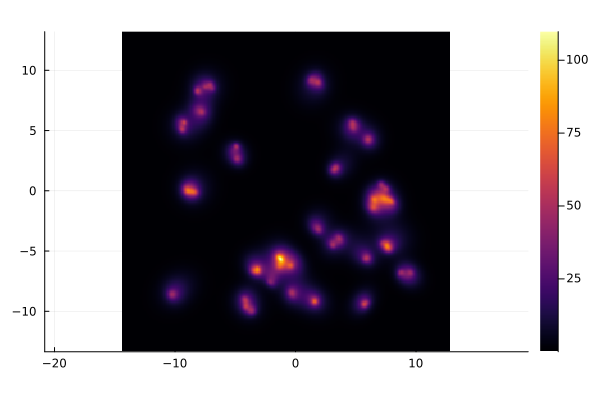

In [20]:
Plots.heatmap(xs, ys, M; z_order=:back, aspect_ratio=:equal)

# Save as .fits

In [9]:
using FITSIO

function write_gaussian_map_fits(filename, M, xs, ys;
                                 ctype1="X",
                                 ctype2="Y",
                                 cunit1="",
                                 cunit2="",
                                 bunit="arb")
    Ny, Nx = size(M)

    delta_x = length(xs) > 1 ? xs[2] - xs[1] : 1.0
    delta_y = length(ys) > 1 ? ys[2] - ys[1] : 1.0
    offset_x = xs[1]
    offset_y = ys[1]

    # Important : on écrit (x,y) dans le FITS
    Mf = permutedims(M, (2, 1))  # taille (Nx, Ny)

    FITS(filename, "w") do f
        write(f, Mf)
        hdu = f[1]

        write_key(hdu, "CTYPE1", ctype1, "Physical axis 1")
        write_key(hdu, "CTYPE2", ctype2, "Physical axis 2")

        if !isempty(cunit1)
            write_key(hdu, "CUNIT1", cunit1, "Unit of axis 1")
        end
        if !isempty(cunit2)
            write_key(hdu, "CUNIT2", cunit2, "Unit of axis 2")
        end

        write_key(hdu, "CRPIX1", 1.0, "Reference pixel axis 1 (FITS, 1-based)")
        write_key(hdu, "CRPIX2", 1.0, "Reference pixel axis 2 (FITS, 1-based)")
        write_key(hdu, "CRVAL1", offset_x, "World coord at reference pixel axis 1")
        write_key(hdu, "CRVAL2", offset_y, "World coord at reference pixel axis 2")
        write_key(hdu, "CDELT1", delta_x, "Pixel scale axis 1")
        write_key(hdu, "CDELT2", delta_y, "Pixel scale axis 2")
        write_key(hdu, "BUNIT",  bunit,   "Data unit")
    end
end

write_gaussian_map_fits (generic function with 1 method)

In [13]:
for axis in (:xy, :xz, :yz)
    xmin, xmax, ymin, ymax = bounding_box_from_ellipses(projections[axis], nsig=4.0)
    Nx = 256
    Ny = 256
    
    xs, ys, delta_x, delta_y, offset_x, offset_y = make_linear_grid(xmin, xmax, ymin, ymax, Nx, Ny)
    
    CRPIX1 = 1.0
    CRPIX2 = 1.0
    CRVAL1 = offset_x
    CRVAL2 = offset_y
    CDELT1 = delta_x
    CDELT2 = delta_y
    
    M = zeros(Float64, Ny, Nx)
    
    for e in projections[axis]
        add_ellipse_gaussian!(M, xs, ys, e; A=10.0)
    end
        
    
    write_gaussian_map_fits(
       "gaussian_map_$(axis).fits",
        M, xs, ys;
        ctype1="X",
        ctype2="Y",
        cunit1="mm",
        cunit2="mm",
        bunit="arb"
    )
end

# Save the ellipses data

In [17]:
using CSV
using DataFrames

import LibGEOS
import GeoInterface as GI

const SIGMA_TO_FWHM = 2 * sqrt(2 * log(2))


function save_ellipses_csv_by_level(projection, levels;
                                    outdir=".",
                                    angle_unit=:rad,
                                    angle_ref="+X axis, counterclockwise")
    mkpath(outdir)

    for level in 1:levels
        df = DataFrame(
            Xpos   = Float64[],
            Ypos   = Float64[],
            A_FWHM = Float64[],
            B_FWHM = Float64[],
            ANG    = Float64[],
        )

        for (xc, yc, sa, sb, ang, l) in projection
            if level == l
                ang_out = angle_unit == :deg ? rad2deg(ang) : ang

                push!(df, (
                    xc,
                    yc,
                    SIGMA_TO_FWHM * sa,
                    SIGMA_TO_FWHM * sb,
                    ang_out
                ))
            end
        end

        filename = joinpath(outdir, "ellipses_level_$(level).csv")

        open(filename, "w") do io
            println(io, "# Xpos, Ypos: ad-hoc coordinates")
            println(io, "# A_FWHM, B_FWHM: full width at half maximum")
            println(io, "# ANG: angle measured from $(angle_ref)")
            println(io, "# ANG_UNIT: $(angle_unit)")
            CSV.write(io, df; append=true, writeheader=true)
        end
    end
end

function save_polygons_csv_by_level(
    projection;
    outdir=".",
    axis="",
    npoints=128,
)
    mkpath(outdir)

    level_values = sort(unique([e.level for e in projection]))

    for level in level_values
        ellipses = filter(e -> e.level == level, projection)
        polygons = ProjectionMapper.merge_overlap(
            ellipses; npoints=npoints,
        )

        df = DataFrame(X=String[], Y=String[])

        for polygon in polygons
            parts = if polygon isa LibGEOS.MultiPolygon
                GI.coordinates(polygon)
            else
                (GI.coordinates(polygon),)
            end

            for rings in parts
                isempty(rings) && continue

                # Exterior contour only; no holes assumed.
                points = rings[1]
                isempty(points) && continue

                x = Float64[p[1] for p in points]
                y = Float64[p[2] for p in points]

                push!(df, (
                    "[" * join(x, ",") * "]",
                    "[" * join(y, ",") * "]",
                ))
            end
        end

        CSV.write(
            joinpath(outdir, "polygons_level_$(level)_$(axis).csv"),
            df,
        )
    end

    return nothing
end

save_polygons_csv_by_level (generic function with 1 method)

In [18]:
for axis in (:xy, :xz, :yz)
    save_polygons_csv_by_level(projections[axis]; axis=axis, outdir="polygons")
end

In [20]:
using CSV, DataFrames
import Plots

function plot_all_polygons(outdir="polygons")
    files = filter(
        name -> occursin(r"^polygons_level_-?\d+\_xy.csv$", name),
        readdir(outdir),
    )

    level_of(name) = parse(
        Int, match(r"level_(-?\d+)", name).captures[1],
    )
    sort!(files; by=level_of)

    function parse_coordinates(value)
        content = strip(chop(strip(String(value)); head=1, tail=1))
        isempty(content) && return Float64[]
        return parse.(Float64, strip.(split(content, ",")))
    end

    p = Plots.plot(
        xlabel="X",
        ylabel="Y",
        aspect_ratio=:equal,
        legend=:outerright,
    )

    colors = Plots.palette(:tab10, max(length(files), 1))

    for (i, filename) in enumerate(files)
        df = CSV.read(joinpath(outdir, filename), DataFrame)
        first_contour = true

        for row in eachrow(df)
            x = parse_coordinates(row.X)
            y = parse_coordinates(row.Y)

            length(x) == length(y) ||
                throw(ArgumentError("X/Y length mismatch in $filename"))

            isempty(x) && continue

            if x[end] != x[1] || y[end] != y[1]
                push!(x, x[1])
                push!(y, y[1])
            end

            Plots.plot!(
                p, x, y;
                color=colors[i],
                linewidth=1.5,
                label=first_contour ? "Level $(level_of(filename))" : "",
            )

            first_contour = false
        end
    end

    return p
end



plot_all_polygons (generic function with 2 methods)

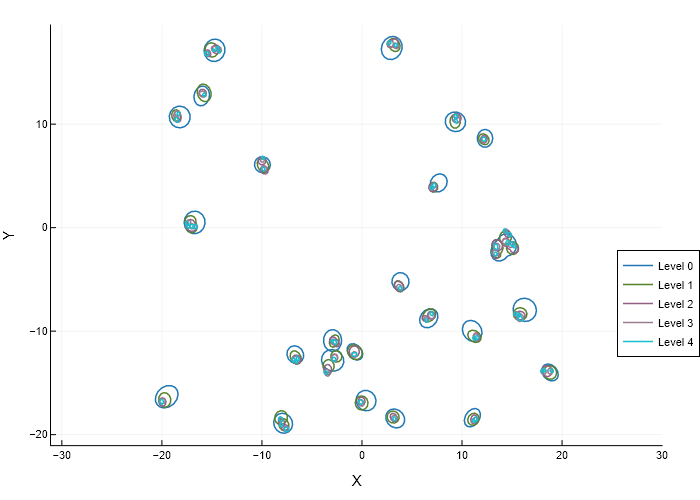

In [21]:
import Plots

Plots.plotly()  # Au lieu de Plots.plotlyjs()

display(plot_all_polygons("polygons"))